# CS 7496 Computer Animation
Copyright (c) Georgia Institute of Technology


---


# Project 5: Twister

![TWISTER](https://upload.wikimedia.org/wikipedia/commons/f/fe/E3_2011_-_IndieCade_Twister_race_%285831107414%29.jpg)

Have you ever played Twister? When you play Twister, your body is essentially solving an inverse kinematics problem. If you're not too familiar with the game, please refer to this video: (https://www.youtube.com/watch?v=7A5XO0udmdo).

In this project, you will create a virtual Twister game by developing an inverse kinematics (IK) solver. Similar to the previous assignments, we will be using PyBullet.(https://docs.google.com/document/d/10sXEhzFRSnvFcl3XxNGhnD4N2SedqwdAvK3dsihxVUA/edit#)

# 1. Set up transformations.

In [1]:
import os
import shutil
from pathlib import Path
from math import sin, cos

import imageio.v2 as iio
from PIL import Image
import numpy as np
import pybullet as p
import pybullet_data as pd

from matplotlib import pyplot as plt
from scipy.optimize import minimize
from scipy.spatial.transform import Rotation as R
from IPython.display import Video, HTML

pybullet build time: Jan 29 2025 23:16:28


Next, we will define the transformations that we will utilize. We will begin by defining a base class, followed by the fixed (0 DOF) and translation (1 DOF) transformations that inherit from this base class.

For simplicity, we do not have a joint with multiple degrees of freedom. This is why our translation and rotation transformations only involve one axis (X/Y/Z) per object. Instead, we will use multiple objects of these types, one for each desired axis, to account for the degrees of freedom we need.

In [2]:
def transform_between(start, end):
    """Helper function to compute the transformation between start and end transformations."""
    if start == end:
        return np.identity(4)
    else:
        return transform_between(start, end.parent) @ end.local_transform()

class Transformation(object):
    """Base class for all transformations."""

    def __init__(self, name=None):
        global transform_list
        transform_list.append(self)
        self.name = name
        self.parent = None  # If parent is None, it is a root node
        self.children = list()
        self.dependent_transformations = set()

    def add(self, child):
        child.parent = self
        self.children.append(child)
        return child

    def global_transform(self):
        return transform_between(None, self)

    def global_position(self):
        return self.global_transform()[:3, 3]

    def local_transform(self):
        raise NotImplementedError

    def local_derivative(self):
        raise NotImplementedError

    def num_dofs(self):
        raise NotImplementedError

    def get_dof_value(self):
        raise NotImplementedError

    def set_dof_value(self, value=0.0):
        raise NotImplementedError

    def __repr__(self):
        return "%s(%s)" % (self.__class__.__name__, self.name)


class Fixed(Transformation):
    """Fixed transformation with no degrees of freedom."""

    def __init__(self, name, tx=0.0, ty=0.0, tz=0.0, rx=0.0, ry=0.0, rz=0.0):
        super().__init__(name=name)
        self._value = np.identity(4)
        self._value[:3, :3] = R.from_euler("xyz", [rx, ry, rz]).as_matrix()
        self._value[:3, 3] = (tx, ty, tz)

    def num_dofs(self):
        return 0

    def local_transform(self):
        return self._value


class Translation(Transformation):
    """Translation transformation with 1 degree of freedom."""

    def __init__(self, name, axis, value=0.0):
        super().__init__(name=name)
        self._value = value
        self.axis = axis
        self.axis_index = "xyz".find(axis)
        self.T = np.identity(4)
        self.dT = np.zeros((4, 4))

    def num_dofs(self):
        return 1

    def get_dof_value(self):
        return self._value

    def set_dof_value(self, value=0.0):
        self._value = value

    def local_transform(self):
        self.T[self.axis_index, 3] = self._value
        return self.T

    def local_derivative(self):
        self.dT[self.axis_index, 3] = 1.0
        return self.dT

## 1.1 Hinge transformation

We have already defined the base class, the fixed transformation, and the translation transformation. Your task is to complete the rotation transformation.

Please implement the `local_transform()` and `local_derivative()` methods as described in their docstrings.

As per the slides, the derivative here is taken with respect to the single free variable of the transformation (as it has 1 DOF). So, for the hinge transformation's `local_derivative()` method, you should return the derivative with respect to the angle of rotation `_theta`.

### 🚩 Task 1 and 2: Write your code below (20 pts) 🚩

In [3]:
class Hinge(Transformation):
    """Rotation transformation with 1 degree of freedom."""

    def __init__(self, name, axis, theta=0.0):
        super().__init__(name=name)
        self._theta = theta
        self.axis = axis
        self.axis_index = "xyz".find(axis)

    def num_dofs(self):
        return 1

    def get_dof_value(self):
        return self._theta

    def set_dof_value(self, value=0.0):
        self._theta = value

    def local_transform(self):
        """Compute the transformation matrix for a rotation operation.

        Uses the current theta value and sin/cos functions to create a rotation
        matrix based on the specified axis.

        Returns:
          transform: The 4x4 transformation matrix.
        """
        cth, sth = cos(self._theta), sin(self._theta)
        ### BEGIN SOLUTION
        # Implementation for three transformation matrices, one for each axis
        if self.axis == "x":
            return np.array(
                [
                    [1.0, 0.0, 0.0, 0.0],
                    [0.0, cth, -sth, 0.0],
                    [0.0, sth, cth, 0.0],
                    [0.0, 0.0, 0.0, 1.0],
                ]
            )
        elif self.axis == "y":
            return np.array(
                [
                    [cth, 0.0, sth, 0.0],
                    [0.0, 1.0, 0.0, 0.0],
                    [-sth, 0.0, cth, 0.0],
                    [0.0, 0.0, 0.0, 1.0],
                ]
            )
        elif self.axis == "z":
            return np.array(
                [
                    [cth, -sth, 0.0, 0.0],
                    [sth, cth, 0.0, 0.0],
                    [0.0, 0.0, 1.0, 0.0],
                    [0.0, 0.0, 0.0, 1.0],
                ]
            )
        ### END SOLUTION

    def local_derivative(self):
        """Compute the derivative of the rotation matrix with respect to theta.

        Returns the derivative matrix for the current axis of rotation.

        Returns:
          deriv_transform: The 4x4 derivative matrix.
        """
        cth, sth = cos(self._theta), sin(self._theta)
        ### BEGIN SOLUTION
        # Implementation of the three derivative matrices
        if self.axis == "x":
            return np.array(
                [
                    [0.0, 0.0, 0.0, 0.0],
                    [0.0, -sth, -cth, 0.0],
                    [0.0, cth, -sth, 0.0],
                    [0.0, 0.0, 0.0, 0.0],
                ]
            )
        elif self.axis == "y":
            return np.array(
                [
                    [-sth, 0.0, cth, 0.0],
                    [0.0, 0.0, 0.0, 0.0],
                    [-cth, 0.0, -sth, 0.0],
                    [0.0, 0.0, 0.0, 0.0],
                ]
            )
        elif self.axis == "z":
            return np.array(
                [
                    [-sth, -cth, 0.0, 0.0],
                    [cth, -sth, 0.0, 0.0],
                    [0.0, 0.0, 0.0, 0.0],
                    [0.0, 0.0, 0.0, 0.0],
                ]
            )
        ### END SOLUTION

Let's test the implementation.

In [4]:
### Unit Tests for Hinge Class
transform_list = list()
test_cases = [
    ("x", 5/12 * np.pi, "75 degrees",
     np.array([[1.0, 0.0, 0.0, 0.0], [0.0, 0.258819, -0.965926, 0.0], [0.0, 0.965926, 0.258819, 0.0], [0.0, 0.0, 0.0, 1.0]]),
     np.array([[0.0, 0.0, 0.0, 0.0], [0.0, -0.965926, -0.258819, 0.0], [0.0, 0.258819, -0.965926, 0.0], [0.0, 0.0, 0.0, 0.0]])),
    ("y", 1/4 * np.pi, "45 degrees",
     np.array([[0.707107, 0.0, 0.707107, 0.0], [0.0, 1.0, 0.0, 0.0], [-0.707107, 0.0, 0.707107, 0.0], [0.0, 0.0, 0.0, 1.0]]),
     np.array([[-0.707107, 0.0, 0.707107, 0.0], [0.0, 0.0, 0.0, 0.0], [-0.707107, 0.0, -0.707107, 0.0], [0.0, 0.0, 0.0, 0.0]])),
    ("z", 1/3 * np.pi, "60 degrees",
     np.array([[0.5, -0.866025, 0.0, 0.0], [0.8660254, 0.5, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0], [0.0, 0.0, 0.0, 1.0]]),
     np.array([[-0.866025, -0.5, 0.0, 0.0], [0.5, -0.866025, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]]))
]

for i, (axis, theta, desc, expected_transform, expected_derivative) in enumerate(test_cases):
    print(f"Test rotation transformation for {axis}-axis with theta = {desc}")
    hinge = Hinge(f"test{i}", axis=axis, theta=theta)

    assert np.allclose(expected_transform, hinge.local_transform(), atol=1e-5), f"Local transformation test{i} failed"
    print(f"Passed local_transform() for test{i}!")

    assert np.allclose(expected_derivative, hinge.local_derivative(), atol=1e-5), f"Local derivative test{i} failed"
    print(f"Passed local_derivative() for test{i}!")
    print("-----------------------")

print("Passed all tests!")

Test rotation transformation for x-axis with theta = 75 degrees
Passed local_transform() for test0!
Passed local_derivative() for test0!
-----------------------
Test rotation transformation for y-axis with theta = 45 degrees
Passed local_transform() for test1!
Passed local_derivative() for test1!
-----------------------
Test rotation transformation for z-axis with theta = 60 degrees
Passed local_transform() for test2!
Passed local_derivative() for test2!
-----------------------
Passed all tests!


In [5]:
### BEGIN HIDDEN TESTS

import numpy as np
import traceback
import time
import copy
from math import sin, cos

# --- Autograder Setup ---
_TOTAL_SCORE_HINGE = 20  # Tasks 1 & 2: 10 points each

__COLOR_RESET = "\x1b[0m"
__COLOR_RED = "\x1b[31m"
__COLOR_GREEN = "\x1b[32m"
__COLOR_BLUE = "\x1b[34m"
__COLOR_CYAN = "\x1b[36m"
__COLOR_YELLOW = "\x1b[33m"

def __soft_assert(
    compare_func,
    test_func_call_obj,
    expected_val_or_func,
    test_args=(),
    expected_args=(),
    expected_type=None,
    expected_shape=None,
    message=""
):
    """
    Executes test_func, compares with expected_val_or_func, handles errors.
    Returns 1 for pass, 0 for fail.
    """
    expected_result = None
    actual_result = None
    try:
        actual_result = test_func_call_obj(*test_args if isinstance(test_args, tuple) else (test_args,))

        if callable(expected_val_or_func):
            expected_result = expected_val_or_func(*expected_args if isinstance(expected_args, tuple) else (expected_args,))
        else:
            expected_result = expected_val_or_func

        if expected_type is not None:
            # ---- accept numpy.bool_ wherever bool is requested ----   # ← ADD
            if expected_type is bool:
                expected_type = (bool, np.bool_)
            # ---------------------------------------------------------
            if not isinstance(actual_result, expected_type):
                raise TypeError(
                    f"Return type is incorrect. "
                    f"Expected {expected_type}, Got {type(actual_result)}."
                )
        if expected_shape is not None and isinstance(actual_result, np.ndarray):
            if actual_result.shape != expected_shape:
                raise ValueError(f"Return shape is incorrect. Expected {expected_shape}, Got {actual_result.shape}.")
        elif expected_shape is not None and not isinstance(actual_result, np.ndarray):
            raise TypeError(f"Shape check requested ({expected_shape}), but result is not a NumPy array (Got {type(actual_result)}).")

        if not compare_func(actual_result, expected_result):
            friendly_message = f"{message}\n{__COLOR_YELLOW}Expected:{__COLOR_RESET} {expected_result}\n{__COLOR_YELLOW}Got:{__COLOR_RESET}      {actual_result}"
            raise AssertionError(friendly_message)
        return 1
    except Exception as e:
        tb_full = traceback.format_exc()
        print(f"\n{__COLOR_RED}========== Test Failed ==========")
        if len(test_args) > 0: 
            print(f"Arguments for test_func: {test_args}")
        if len(expected_args) > 0 and callable(expected_val_or_func):
            print(f"Arguments for expected_func: {expected_args}")
        if expected_result is not None:
            print(f"Expected Result: {expected_result}")
        if actual_result is not None:
            print(f"Actual Result: {actual_result}")
        print(f"Error Type: {type(e).__name__}")
        print(f"Error Message: {e}")
        print("Traceback (relevant part):")
        # Filter out internal assert and run_tests frames for brevity
        tb_lines = tb_full.splitlines()
        filtered_tb = [line for line in tb_lines if "__soft_assert" not in line and "__run_tests" not in line]
        print("\n".join(filtered_tb))
        print("================================" + __COLOR_RESET + "\n")
        return 0

def __print_test_header(test_num, description):
    """Prints a formatted header for each test."""
    print(f"\n{__COLOR_CYAN}===== Test {test_num}: {description} ====={__COLOR_RESET}")

def __run_tests(test_cases_list, points_per_test_case, class_to_test=None):
    """Runs test cases and returns the total score."""
    total_defined_tests = len(test_cases_list)
    passed_count = 0
    current_score = 0.0
    start_time = time.time()

    if class_to_test is not None:
        try:
            _ = class_to_test
        except NameError:
            print(f"\n{__COLOR_RED}CRITICAL ERROR: Class not found.{__COLOR_RESET}")
            print(f"{__COLOR_YELLOW}Cannot run tests. Score: 0{__COLOR_RESET}")
            return 0.0

    for i, case_details in enumerate(test_cases_list):
        num = i + 1
        short_desc, error_msg, test_lambda, expected_lambda_or_val, \
        test_lambda_args, expected_lambda_args, \
        comp_func, comp_kwargs, e_type, e_shape = case_details

        __print_test_header(num, short_desc)

        # Add tolerance to comparison function if it's np.allclose or np.isclose
        current_comp_kwargs = comp_kwargs.copy()
        if comp_func == np.allclose or comp_func == np.isclose:
            if 'atol' not in current_comp_kwargs:
                current_comp_kwargs.setdefault('atol', 1e-6)

        pass_status = __soft_assert(
            lambda actual, expected: comp_func(actual, expected, **current_comp_kwargs),
            test_lambda,
            expected_lambda_or_val,
            test_args=test_lambda_args,
            expected_args=expected_lambda_args,
            expected_type=e_type,
            expected_shape=e_shape,
            message=error_msg
        )
        if pass_status == 1:
            passed_count += 1
            current_score += points_per_test_case
            print(f"{__COLOR_GREEN}Test {num} Passed.{__COLOR_RESET}")

    elapsed_time = time.time() - start_time
    failed_count = total_defined_tests - passed_count

    summary_color = __COLOR_GREEN if failed_count == 0 else __COLOR_RED
    print(f"{summary_color}\n========== Summary: {passed_count}/{total_defined_tests} tests passed in {elapsed_time:.2f}s =========={__COLOR_RESET}")

    # Ensure score does not exceed max due to float precision
    final_score = round(current_score, 2)
    return final_score

# --- Expected Functions for Hinge ---
def _expected_hinge_transform(axis, theta):
    """Generate expected transformation matrix for a given axis and angle."""
    cth, sth = cos(theta), sin(theta)

    if axis == "x":
        return np.array([
            [1.0, 0.0, 0.0, 0.0],
            [0.0, cth, -sth, 0.0],
            [0.0, sth, cth, 0.0],
            [0.0, 0.0, 0.0, 1.0]
        ], dtype=np.float64)
    elif axis == "y":
        return np.array([
            [cth, 0.0, sth, 0.0],
            [0.0, 1.0, 0.0, 0.0],
            [-sth, 0.0, cth, 0.0],
            [0.0, 0.0, 0.0, 1.0]
        ], dtype=np.float64)
    elif axis == "z":
        return np.array([
            [cth, -sth, 0.0, 0.0],
            [sth, cth, 0.0, 0.0],
            [0.0, 0.0, 1.0, 0.0],
            [0.0, 0.0, 0.0, 1.0]
        ], dtype=np.float64)

def _expected_hinge_derivative(axis, theta):
    """Generate expected derivative matrix for a given axis and angle."""
    cth, sth = cos(theta), sin(theta)

    if axis == "x":
        return np.array([
            [0.0, 0.0, 0.0, 0.0],
            [0.0, -sth, -cth, 0.0],
            [0.0, cth, -sth, 0.0],
            [0.0, 0.0, 0.0, 0.0]
        ], dtype=np.float64)
    elif axis == "y":
        return np.array([
            [-sth, 0.0, cth, 0.0],
            [0.0, 0.0, 0.0, 0.0],
            [-cth, 0.0, -sth, 0.0],
            [0.0, 0.0, 0.0, 0.0]
        ], dtype=np.float64)
    elif axis == "z":
        return np.array([
            [-sth, -cth, 0.0, 0.0],
            [cth, -sth, 0.0, 0.0],
            [0.0, 0.0, 0.0, 0.0],
            [0.0, 0.0, 0.0, 0.0]
        ], dtype=np.float64)

# --- Test Cases for Hinge ---
hinge_test_cases = [
    # Task 1: local_transform tests
    (
        "Hinge Transform: X-axis, theta=0",
        "Hinge transform for X-axis with theta=0 is incorrect.",
        lambda: Hinge("test", "x", 0.0).local_transform(),
        lambda: _expected_hinge_transform("x", 0.0),
        (), (),
        np.allclose, {"atol": 1e-10}, np.ndarray, (4, 4)
    ),
    (
        "Hinge Transform: X-axis, theta=pi/2",
        "Hinge transform for X-axis with theta=pi/2 is incorrect.",
        lambda: Hinge("test", "x", np.pi/2).local_transform(),
        lambda: _expected_hinge_transform("x", np.pi/2),
        (), (),
        np.allclose, {"atol": 1e-10}, np.ndarray, (4, 4)
    ),
    (
        "Hinge Transform: Y-axis, theta=pi/4",
        "Hinge transform for Y-axis with theta=pi/4 is incorrect.",
        lambda: Hinge("test", "y", np.pi/4).local_transform(),
        lambda: _expected_hinge_transform("y", np.pi/4),
        (), (),
        np.allclose, {"atol": 1e-10}, np.ndarray, (4, 4)
    ),
    (
        "Hinge Transform: Z-axis, theta=-pi/3",
        "Hinge transform for Z-axis with theta=-pi/3 is incorrect.",
        lambda: Hinge("test", "z", -np.pi/3).local_transform(),
        lambda: _expected_hinge_transform("z", -np.pi/3),
        (), (),
        np.allclose, {"atol": 1e-10}, np.ndarray, (4, 4)
    ),
    # Task 2: local_derivative tests
    (
        "Hinge Derivative: X-axis, theta=0",
        "Hinge derivative for X-axis with theta=0 is incorrect.",
        lambda: Hinge("test", "x", 0.0).local_derivative(),
        lambda: _expected_hinge_derivative("x", 0.0),
        (), (),
        np.allclose, {"atol": 1e-10}, np.ndarray, (4, 4)
    ),
    (
        "Hinge Derivative: Y-axis, theta=pi/6",
        "Hinge derivative for Y-axis with theta=pi/6 is incorrect.",
        lambda: Hinge("test", "y", np.pi/6).local_derivative(),
        lambda: _expected_hinge_derivative("y", np.pi/6),
        (), (),
        np.allclose, {"atol": 1e-10}, np.ndarray, (4, 4)
    ),
    (
        "Hinge Derivative: Z-axis, theta=2*pi/3",
        "Hinge derivative for Z-axis with theta=2*pi/3 is incorrect.",
        lambda: Hinge("test", "z", 2*np.pi/3).local_derivative(),
        lambda: _expected_hinge_derivative("z", 2*np.pi/3),
        (), (),
        np.allclose, {"atol": 1e-10}, np.ndarray, (4, 4)
    ),
    (
        "Hinge Transform returns new array",
        "Hinge transform should return a new array, not modify in-place.",
        lambda: Hinge("test", "x", 0.5).local_transform() is not Hinge("test", "x", 0.5).local_transform(),
        lambda: True,
        (), (),
        lambda x, y: x == y, {}, bool, None
    ),
]

# Run tests
num_test_cases = len(hinge_test_cases)
points_per_case = _TOTAL_SCORE_HINGE / num_test_cases if num_test_cases > 0 else 0

print(f"{__COLOR_BLUE}Running tests for Hinge Transformation...{__COLOR_RESET}")
hinge_score = __run_tests(hinge_test_cases, points_per_case, Hinge)
hinge_score

### END HIDDEN TESTS

Running tests for Hinge Transformation...

===== Test 1: Hinge Transform: X-axis, theta=0 =====
Test 1 Passed.

===== Test 2: Hinge Transform: X-axis, theta=pi/2 =====
Test 2 Passed.

===== Test 3: Hinge Transform: Y-axis, theta=pi/4 =====
Test 3 Passed.

===== Test 4: Hinge Transform: Z-axis, theta=-pi/3 =====
Test 4 Passed.

===== Test 5: Hinge Derivative: X-axis, theta=0 =====
Test 5 Passed.

===== Test 6: Hinge Derivative: Y-axis, theta=pi/6 =====
Test 6 Passed.

===== Test 7: Hinge Derivative: Z-axis, theta=2*pi/3 =====
Test 7 Passed.

===== Test 8: Hinge Transform returns new array =====
Test 8 Passed.

========== Summary: 8/8 tests passed in 0.00s ==========


20.0

# 2. Set up the skeleton.

We will now set up the structure of the character, also called the skeleton.

In [6]:
### Skeleton Setup Function

# Global structure
transform_list = list()
name_to_transform = dict()
transform_list_1dof = list()
motion = list()


def setup_character():
    global transform_list, name_to_transform, transform_list_1dof
    # Reset the data structure
    transform_list = list()
    name_to_transform = dict()
    transform_list_1dof = list()
    motion = list()

    # Define the character
    base = (
        Translation("j_tx", axis="x")
        .add(Translation("j_ty", axis="y"))
        .add(Translation("j_tz", axis="z"))
        .add(Hinge("j_rx", axis="x"))
        .add(Hinge("j_ry", axis="y"))
        .add(Hinge("j_rz", axis="z"))
        .add(Fixed("base"))
    )
    base.add(Fixed("head", tz=0.5))
    for d in ["l", "r"]:
        sx = 1.0 if d == "l" else -1.0
        base.add(Fixed("%s_base_to_shoulder" % d, tx=sx * 0.2, tz=0.25)).add(
            Hinge("j_%s_shoulder_x" % d, "x", 0.0)
        ).add(Hinge("j_%s_shoulder_y" % d, "y", 0.0)).add(
            Hinge("j_%s_shoulder_z" % d, "z", 0.0)
        ).add(Fixed("%s_upperarm1" % d, tx=sx * 0.15)).add(
            Fixed("%s_upperarm2" % d, tx=sx * 0.15)
        ).add(Hinge("j_%s_elbow" % d, "z", 0.0)).add(
            Fixed("%s_lowerarm1" % d, tx=sx * 0.15)
        ).add(Fixed("%s_lowerarm2" % d, tx=sx * 0.15)).add(
            Fixed("%s_hand" % d, tx=sx * 0.1)
        )
    for d in ["l", "r"]:
        sx = 1.0 if d == "l" else -1.0
        base.add(Fixed("%s_base_to_hip" % d, tx=sx * 0.13, tz=-0.3)).add(
            Hinge("j_%s_hip_x" % d, "x", 0.0)
        ).add(Hinge("j_%s_hip_y" % d, "y", 0.0)).add(
            Hinge("j_%s_hip_z" % d, "z", 0.0)
        ).add(Fixed("%s_thigh1" % d, tz=-0.2)).add(Fixed("%s_thigh2" % d, tz=-0.2)).add(
            Hinge("j_%s_knee" % d, "x", 0.0)
        ).add(Fixed("%s_shin1" % d, tz=-0.2)).add(Fixed("%s_shin2" % d, tz=-0.2)).add(
            Hinge("j_%s_ankle" % d, "x", 0.0)
        ).add(Fixed("%s_feet" % d, ty=-0.12))

    # Build auxiliary data structures
    for tr in transform_list:
        name_to_transform[tr.name] = tr
        if tr.num_dofs() == 1:
            transform_list_1dof.append(tr)

    # Build dependent transformations.
    # Each joint depends on itself (if it has a DOF) as well as all its ancestors with DOFs in the skeleton hierarchy.
    for tr in transform_list:
        tr.dependent_transformations = (
            tr.parent.dependent_transformations.copy() if tr.parent else set()
        )

        if tr.num_dofs() == 1:
            tr.dependent_transformations.add(tr)

Let us now visualize our skeleton using PyBullet. In order to do this, we first define a base class for Rigid bodies. We then define classes for the various parts of our skeleton, namely the Box and Sphere classes, which inherit from the RigidBody class. We then use each of these components to setup the skeleton.

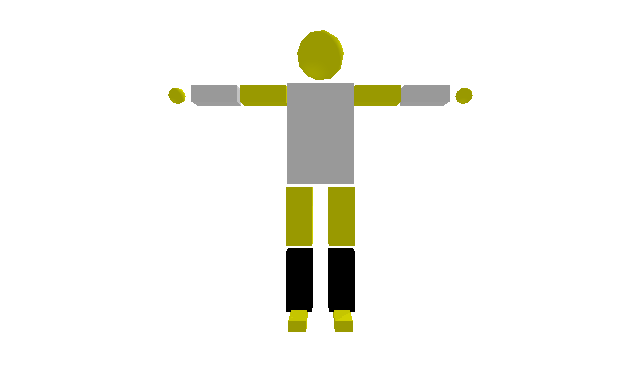

In [7]:
### Rigidbody Setup & Visualization (PyBullet)

p.connect(p.DIRECT)
p.resetSimulation()

# Set up camera parameters for visualization
pixelWidth = 640
pixelHeight = 368
viewMatrix = p.computeViewMatrixFromYawPitchRoll(
    cameraTargetPosition=[0, 0, -0.3],
    distance=2.0,
    yaw=0.0,
    pitch=0.0,
    roll=0.0,
    upAxisIndex=2,
)
projectionMatrix = p.computeProjectionMatrixFOV(
    fov=60, aspect=pixelWidth / pixelHeight, nearVal=0.01, farVal=100
)

body_list = list()
target_body_list = list()


class RigidBody(object):
    """Base class for rigid bodies in the PyBullet simulation."""

    def __init__(self, transform):
        global body_list
        self.transform = transform
        self.uid = -1
        body_list.append(self)

    def get_position_and_orientation(self):
        T = self.transform.global_transform()
        position = T[:3, 3]
        orientation = R.from_matrix(T[:3, :3]).as_quat()
        return position, orientation

    def update_pybullet(self):
        position, orientation = self.get_position_and_orientation()
        p.resetBasePositionAndOrientation(self.uid, position, orientation)


class Box(RigidBody):
    """Creates box-shaped rigid bodies for the torso and limbs of our character."""

    def __init__(
        self,
        transform,
        color=np.array([0, 1, 1, 1]),
        half_extends=[1, 1, 1],
        texUid=None,
    ):
        super().__init__(transform)

        self.visualId = p.createVisualShape(
            p.GEOM_BOX,
            halfExtents=half_extends,
            rgbaColor=color,
            specularColor=[1, 1, 1],
        )
        position, orientation = self.get_position_and_orientation()
        self.uid = p.createMultiBody(1.0, -1, self.visualId, position, orientation)
        if texUid:
            p.changeVisualShape(self.uid, -1, textureUniqueId=texUid)


class Sphere(RigidBody):
    """Creates sphere-shaped rigid bodies for the hands and head of our character."""

    def __init__(self, transform, color=np.array([0, 1, 1, 1]), radius=1.0):
        super().__init__(transform)
        self.radius = radius

        self.visualId = p.createVisualShape(
            p.GEOM_SPHERE, radius=radius, rgbaColor=color, specularColor=[1, 1, 1]
        )
        position, orientation = self.get_position_and_orientation()
        self.uid = p.createMultiBody(1.0, -1, self.visualId, position, orientation)


def reset_simulation():
    global body_list
    time = 0
    p.resetSimulation()
    p.setGravity(0, 0, 0)
    p.setTimeStep(1e-6)  # Dummy time step
    body_list = list()


def create_rigid_bodies():
    global name_to_transform, target_body_list
    black_rgba = [0, 0, 0, 0.64]
    white_rgba = [1, 1, 1, 0.64]
    yellow_rgba = [1, 1, 0, 0.64]
    # Create rigid bodies for visualization
    Box(name_to_transform["base"], half_extends=[0.2, 0.1, 0.3], color=white_rgba)

    Sphere(name_to_transform["head"], radius=0.15, color=yellow_rgba)
    for d in ["l", "r"]:
        Box(
            name_to_transform["%s_upperarm1" % d],
            half_extends=[0.14, 0.05, 0.05],
            color=yellow_rgba,
        )
        Box(
            name_to_transform["%s_lowerarm1" % d],
            half_extends=[0.14, 0.05, 0.05],
            color=white_rgba,
        )
        Sphere(name_to_transform["%s_hand" % d], radius=0.05, color=yellow_rgba)
        Box(
            name_to_transform["%s_thigh1" % d],
            half_extends=[0.08, 0.06, 0.18],
            color=yellow_rgba,
        )
        Box(
            name_to_transform["%s_shin1" % d],
            half_extends=[0.08, 0.06, 0.18],
            color=black_rgba,
        )
        Box(
            name_to_transform["%s_feet" % d],
            half_extends=[0.05, 0.10, 0.03],
            color=yellow_rgba,
        )

    # Create target spheres for IK constraints
    max_targets = 10
    for i in range(max_targets):
        visualId = p.createVisualShape(
            p.GEOM_SPHERE,
            radius=0.06,
            rgbaColor=[1.0, 0.0, 0.0, 1.0],
            specularColor=[1, 1, 1],
        )
        uid = p.createMultiBody(
            1.0, -1, visualId, [100.0, 100.0, 100.0], [0.0, 0.0, 0.0, 1.0]
        )
        target_body_list.append(uid)


setup_character()
reset_simulation()
create_rigid_bodies()

_, _, img, _, _ = p.getCameraImage(
    pixelWidth,
    pixelHeight,
    viewMatrix,
    projectionMatrix,
    shadow=1,
    lightDirection=[1, 1, 1],
)

Image.fromarray(img)

We will now define some helper functions that will allow us to connect the pose vector and the skeleton `Transformation`s.

In [8]:
### Pose ↔ Transformation Helper Functions

def set_joint_positions(q):
    global transform_list_1dof
    assert len(q) == len(transform_list_1dof)
    for q_i, jnt_i in zip(q, transform_list_1dof):
        jnt_i.set_dof_value(value=q_i)


def get_joint_positions():
    global transform_list_1dof
    return np.array([jnt_i.get_dof_value() for jnt_i in transform_list_1dof])

# 3. Inverse Kinematics
Now that we have all the required machinery in place, we will work on the final piece of the puzzle: the IK solver.

## 3.1 Jacobian function

First, please implement the `compute_jacobian()` function according to its docstring, referring to the lecture slides. 

Specifically, given an end effector's `Transformation` (at a leaf of the skeleton hierarchy), this function should return the Jacobian of the constrained point (3D) on the end effector with respect to the skeleton's pose vector (i.e., the values of all its DOFs). So, its shape should be `(3, n_dofs)`.

The key idea is to use these quantities for each joint that the end effector depends on:
1. The transformations up the kinematic chain, from the immediate parent to the root
2. The local derivative with respect to the joint's own DOF value
3. The transformations down the kinematic chain, from the joint itself to the end effector
4. Finally, the position of the constrained point in the end effector's local coordinate space ($\mathbf{h}_0$ in the slides)
    - This one is trivial in our case: *we (arbitrarily) define the constrained point to be at the origin of this local space.*

Some hints based on what the code has already computed for you so far:

- `transform_list_1dof` is a global list of transformations in the skeleton that have 1 DOF.
    - The Jacobian's columns correspond to the joints in this list only; no other joints are relevant to any Jacobian.
    - This list has been computed for you when the skeleton was built inside `setup_character()`.

- Each `Transformation` has a member variable `dependent_transformations`: a set of all `Transformation`s whose DOFs it depends on.
    - So, for a joint `j`, any joint outside the set `j.dependent_transformations` will also be irrelevant to the Jacobian of `j`.
    - This set has been computed for you for each `Transformation` in the skeleton, again inside `setup_character()`.

### 🚩 Task 3: Write your code below (20 pts) 🚩

In [9]:
def compute_jacobian(end_effector):
    """Compute the Jacobian of the end effector.

    Uses global_transform(), local_derivative(), and transform_between() functions
    to compute the Jacobian matrix. Handles the case when the joint is not in
    end_effector.dependent_transformations. Note that each joint has only one
    degree of freedom.

    Args:
      end_effector: Component for which we want to find the Jacobian

    Returns:
      J: Jacobian matrix of shape (3, n_dofs)
    """
    global transform_list_1dof
    n_dofs = len(transform_list_1dof)
    h0 = np.array([0.0, 0.0, 0.0, 1.0])  # Local point in homogeneous coordinates
    J = np.zeros((3, n_dofs))
    for i, jnt_i in enumerate(transform_list_1dof):
        # Skip if joint doesn't affect this end effector
        if jnt_i not in end_effector.dependent_transformations:
            continue
        # Step 0: Compute T_parent (transformation of the parent node)
        if jnt_i.parent:  # Check if the joint has a parent (not None)
            # T_parent is the global transformation of the parent node
            T_parent = jnt_i.parent.global_transform()
        else:
            T_parent = np.identity(4)  # If the joint has no parent

        ### BEGIN SOLUTION
        # Step 1: Compute dTdq - the local derivative of the current joint
        dTdq = jnt_i.local_derivative()
        # Step 2: Compute T_child - transformation from jnt_i to end_effector
        T_child = transform_between(jnt_i, end_effector)
        # Step 3: Compute dx_dq using the chain rule
        dx_dq = T_parent @ dTdq @ T_child @ h0
        ### END SOLUTION

        # Extract the first three components (position)
        J[:, i] = dx_dq[:3]
    return J

Let's test the Jacobian function.

In [10]:
### Unit Tests for compute_jacobian()
n_dofs = len(transform_list_1dof)
eps = 1e-4
q = np.random.rand(n_dofs) - 0.5
set_joint_positions(q)

def _verify_jacobian_column(end_effector, joint, q_val, col_idx, jacobian):
    """Verify single Jacobian column using finite differences."""
    joint.set_dof_value(q_val + eps)
    x_plus = end_effector.global_position()
    joint.set_dof_value(q_val - eps)
    x_minus = end_effector.global_position()
    joint.set_dof_value(q_val)

    analytical = jacobian[:, col_idx]
    numerical = (x_plus - x_minus) / (2 * eps)

    assert np.allclose(analytical, numerical, atol=1e-6), \
        f"Jacobian column {col_idx} mismatch for {end_effector}"

for effector_name in ["l_hand", "r_feet", "head"]:
    effector = name_to_transform[effector_name]
    jacobian = compute_jacobian(effector)

    for i, joint in enumerate(transform_list_1dof):
        _verify_jacobian_column(effector, joint, q[i], i, jacobian)

    print(f"Passed - {effector_name}")

print("All Jacobian tests passed!")
print("Please note that this does not serve as proof that it can pass all hidden test cases.")

Passed - l_hand
Passed - r_feet
Passed - head
All Jacobian tests passed!
Please note that this does not serve as proof that it can pass all hidden test cases.


In [11]:
### BEGIN HIDDEN TESTS

import numpy as np, time, traceback
from math import isfinite

# --------------------------------------------------------------------
# Numeric Jacobian
# --------------------------------------------------------------------
def _numeric_jacobian(end_eff, eps=1e-6):
    q0   = get_joint_positions()
    n    = len(q0)
    p0   = end_eff.global_position()
    Jnum = np.zeros((3,n))
    for k in range(n):
        q = q0.copy(); q[k] += eps
        set_joint_positions(q)
        Jnum[:,k] = (end_eff.global_position()-p0)/eps
    set_joint_positions(q0)
    return Jnum

# --------------------------------------------------------------------
#  Lambda helpers
# --------------------------------------------------------------------
def _shape(end_name):
    setup_character()
    J = compute_jacobian(name_to_transform[end_name])
    return J.shape

def _fd_ok(end_name, seed=0):
    np.random.seed(seed)
    setup_character()
    end_eff = name_to_transform[end_name]
    q = np.random.uniform(-1.0,1.0,len(transform_list_1dof))
    set_joint_positions(q)
    return np.allclose(compute_jacobian(end_eff), _numeric_jacobian(end_eff), atol=5e-5)

def _independent_zero(end_name):
    setup_character()
    eff = name_to_transform[end_name]
    J   = compute_jacobian(eff)
    zero_cols = [i for i,j in enumerate(transform_list_1dof)
                 if j not in eff.dependent_transformations]
    return np.allclose(J[:,zero_cols],0.0,atol=1e-10)

def _fresh(end_name):
    setup_character()
    eff = name_to_transform[end_name]
    return compute_jacobian(eff) is not compute_jacobian(eff)

def _root_translation_columns(random_rot=False):
    setup_character()
    if random_rot:
        set_joint_positions(np.array(
            [0,0,0]+list(np.random.uniform(-1,1,3))+[0]*(len(transform_list_1dof)-6)
        ))  # random rx,ry,rz
    eff = name_to_transform["base"]
    J   = compute_jacobian(eff)
    cols_ok = (np.allclose(J[:,0],[1,0,0],atol=1e-10) and
               np.allclose(J[:,1],[0,1,0],atol=1e-10) and
               np.allclose(J[:,2],[0,0,1],atol=1e-10))
    return cols_ok

# --------------------------------------------------------------------
# Test cases
# --------------------------------------------------------------------
jac_test_cases = [
    # fresh array
    ("Shape check l_hand", "Wrong shape.", lambda: _shape("l_hand"),
     lambda: (3,len(transform_list_1dof)), (), (), lambda a,e: a==e, {}, tuple, None),
    ("Returns fresh ndarray", "Must return new array, not cached.",
     lambda: _fresh("l_hand"), lambda: True, (), (), lambda a,e: a==e, {}, bool, None),

    # Finite diff agreement
    ("FD agreement l_hand", "Mismatch vs finite diff (l_hand).",
     lambda: _fd_ok("l_hand",seed=1), lambda: True, (), (), lambda a,e: a==e, {}, bool, None),
    ("FD agreement r_hand", "Mismatch vs finite diff (r_hand).",
     lambda: _fd_ok("r_hand",seed=2), lambda: True, (), (), lambda a,e: a==e, {}, bool, None),
    ("FD agreement l_feet", "Mismatch vs finite diff (l_feet).",
     lambda: _fd_ok("l_feet",seed=3), lambda: True, (), (), lambda a,e: a==e, {}, bool, None),
    ("FD agreement r_feet", "Mismatch vs finite diff (r_feet).",
     lambda: _fd_ok("r_feet",seed=4), lambda: True, (), (), lambda a,e: a==e, {}, bool, None),

    # Single DOF zero-column
    ("Zero columns for head", "Independent DOFs should give zero columns.",
     lambda: _independent_zero("head"), lambda: True, (), (), lambda a,e: a==e, {}, bool, None),

    # Base translation
    ("Base translation columns (identity rot)",
     "j_tx/j_ty/j_tz columns should be unit basis.",
     _root_translation_columns, lambda: True, (), (), lambda a,e: a==e, {}, bool, None),
    ("Base translation columns (after random rot)",
     "Translation columns must remain unit even after downstream rotations.",
     lambda: _root_translation_columns(random_rot=True), lambda: True, (), (), lambda a,e: a==e, {}, bool, None),
]

# --------------------------------------------------------------------
#  Run tests
# --------------------------------------------------------------------
_TOTAL_SCORE_JAC = 20
_pts = _TOTAL_SCORE_JAC / len(jac_test_cases)

print(f"{__COLOR_BLUE}Running extended tests for compute_jacobian...{__COLOR_RESET}")
jacobian_score = __run_tests(jac_test_cases, _pts)
jacobian_score

### END HIDDEN TESTS


Running extended tests for compute_jacobian...

===== Test 1: Shape check l_hand =====
Test 1 Passed.

===== Test 2: Returns fresh ndarray =====
Test 2 Passed.

===== Test 3: FD agreement l_hand =====
Test 3 Passed.

===== Test 4: FD agreement r_hand =====
Test 4 Passed.

===== Test 5: FD agreement l_feet =====
Test 5 Passed.

===== Test 6: FD agreement r_feet =====
Test 6 Passed.

===== Test 7: Zero columns for head =====
Test 7 Passed.

===== Test 8: Base translation columns (identity rot) =====
Test 8 Passed.

===== Test 9: Base translation columns (after random rot) =====
Test 9 Passed.

========== Summary: 9/9 tests passed in 0.03s ==========


20.0

## 3.2 Objective and gradient functions.
Next, please implement the objective and gradient functions according to the respective docstrings. The gradient should be computed with respect to the pose of the skeleton, which is now referred to as `x` in the code instead of `q`.

### 🚩 Task 4 and 5: write your code below (40 pts) 🚩 

In [12]:
end_effectors = [name_to_transform["l_hand"], name_to_transform["r_feet"]]
targets = [np.array((1.2, -0.3, 0.4)), np.array((0.0, -0.2, 0.1))]


def objective_function(x):
    """Compute the objective function for IK optimization.

    Implements the objective function of the form 0.5 * L2_norm(error)^2, where
    the error is the difference between each position and its target.
    Adds contributions from all position/target pairs.

    Assumes no additional objective (g(q) = 0).

    Args:
      x: Pose vector

    Returns:
      ret: The scalar value of the objective function
    """
    global end_effectors, targets, motion
    motion.append(np.array(x))
    set_joint_positions(x)  # Set the joint positions: q=x
    ret = 0.0
    for end_effector, target in zip(end_effectors, targets):
        ### BEGIN SOLUTION
        # Step 1: Get the global position of the current end effector, h(q)
        position = end_effector.global_position()
        # Step 2: Compute the squared error |h(q) - p|^2, where p is the target
        ret += 0.5 * np.linalg.norm(position - target) ** 2
        ### END SOLUTION
    return ret


def gradient_function(x):
    """Compute the gradient of the objective function.

    Uses global_position() and compute_jacobian() to compute the gradient
    with respect to the pose vector.

    Args:
      x: Pose vector

    Returns:
      grad: The gradient vector of length len(x)
    """
    global end_effectors, targets
    set_joint_positions(x)
    grad = np.zeros(len(x))
    for end_effector, target in zip(end_effectors, targets):
        ### BEGIN SOLUTION
        # Step 1: Get the position of the end effector h(q)
        position = end_effector.global_position()
        # Step 2: Compute the Jacobian J
        J = compute_jacobian(end_effector)
        # Step 3: Compute the gradient as J^T C, where C = h(q) - p
        grad += (position - target) @ J
        ### END SOLUTION
    return grad

We test the objective and gradient implementation.

In [13]:
### Unit Tests for Objective & Gradient Functions

def numerical_gradient(func, x, eps=1e-6):
    """Compute numerical gradient using central difference"""
    grad = np.zeros_like(x)
    for i in range(len(x)):
        x_plus = x.copy()
        x_minus = x.copy()
        x_plus[i] += eps
        x_minus[i] -= eps
        grad[i] = (func(x_plus) - func(x_minus)) / (2 * eps)
    return grad

def test_gradient_accuracy():
    """Test analytical gradient against numerical approximation"""
    n_tests = 10
    eps = 1e-6
    tolerance = 1e-5

    for test_id in range(n_tests):
        x0 = np.random.uniform(-10.0, 10.0, n_dofs)

        analytical_grad = gradient_function(x0)
        numerical_grad = numerical_gradient(objective_function, x0, eps)

        if not np.allclose(analytical_grad, numerical_grad, atol=tolerance):
            print(f"Test {test_id} failed: max diff = {np.max(np.abs(analytical_grad - numerical_grad))}")
            return False

    print(f"All {n_tests} gradient tests passed!")
    return True

test_gradient_accuracy()

All 10 gradient tests passed!


True

In [14]:
### BEGIN HIDDEN TESTS

# ---------------------------------------------------------------------
# 2)  Numerical gradient helper ---------------------------------------
# ---------------------------------------------------------------------
def _numeric_grad(f, x, h=1e-7):
    g = np.zeros_like(x)
    f0 = f(x)
    for k in range(len(x)):
        x_step = x.copy(); x_step[k] += h
        g[k] = (f(x_step) - f0) / h
    return g

# ---------------------------------------------------------------------
# 3)  Small utility lambdas for individual checks ---------------------
# ---------------------------------------------------------------------
def _fresh_character(seed=0):
    """Reset skeleton & generate a random pose in [-0.8,0.8]."""
    np.random.seed(seed)
    setup_character()
    pose = np.random.uniform(-0.8, 0.8, len(transform_list_1dof))
    return pose

# 3-A Objective: returns scalar
def _obj_scalar():
    pose = _fresh_character()
    return isinstance(objective_function(pose), (float, np.floating))

# 3-B Objective: non-negative
def _obj_nonneg():
    pose = _fresh_character(1)
    return objective_function(pose) >= 0.0

# 3-C Gradient shape
def _grad_shape():
    pose = _fresh_character(2)
    return gradient_function(pose).shape

# 3-D Gradient finite values
def _grad_finite():
    pose = _fresh_character(3)
    g = gradient_function(pose)
    return np.all(np.isfinite(g))

# 3-E Gradient fresh ndarray
def _grad_fresh():
    pose = _fresh_character(4)
    return gradient_function(pose) is not gradient_function(pose)

# 3-F motion logging increments by exactly 1 per call
def _motion_log():
    pose = _fresh_character(5)
    before = len(motion)
    objective_function(pose)
    after  = len(motion)
    objective_function(pose)
    return (after == before + 1) and (len(motion) == after + 1)

# 3-G Analytic = numeric gradient (seed 6)
def _grad_matches_fd(seed=6):
    pose = _fresh_character(seed)
    g_anal = gradient_function(pose)
    g_num  = _numeric_grad(objective_function, pose)
    return np.allclose(g_anal, g_num, atol=5e-4)

# 3-H Another seed check for robustness
def _grad_matches_fd2(seed=11):
    pose = _fresh_character(seed)
    return np.allclose(gradient_function(pose),
                       _numeric_grad(objective_function, pose),
                       atol=5e-4)

# 3-I  One-step descent should reduce objective
def _descent_step_reduces():
    pose = _fresh_character(7)
    g = gradient_function(pose)
    new_pose = pose - 1e-3 * g
    return objective_function(new_pose) < objective_function(pose)

# 3-J  Gradient idempotency (same pose, same result)
def _grad_idempotent():
    pose = _fresh_character(8)
    g1 = gradient_function(pose)
    g2 = gradient_function(pose)
    return np.allclose(g1, g2)

# ---------------------------------------------------------------------
# 4)  Assemble the 10 test cases --------------------------------------
# ---------------------------------------------------------------------
ik_tests = [
    ("Objective returns scalar",            "objective_function must return a scalar.",
     _obj_scalar,          lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),

    ("Objective is non-negative",           "objective_function should never return <0.",
     _obj_nonneg,          lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),

    ("Gradient correct length",             "gradient length ≠ #DOFs.",
     _grad_shape,          lambda: (len(transform_list_1dof),),
     (), (), lambda a,e: a==e, {}, tuple, None),

    ("Gradient finite",                     "gradient contains NaN/Inf.",
     _grad_finite,         lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),

    ("Gradient returns fresh array",        "gradient_function should return new ndarray.",
     _grad_fresh,          lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),

    ("motion appended per call",            "motion list length should grow by 1 per call.",
     _motion_log,          lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),

    ("Analytic = numeric grad (seed 6)",    "Analytic vs FD mismatch (seed 6).",
     _grad_matches_fd,     lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),

    ("Analytic = numeric grad (seed 11)",   "Analytic vs FD mismatch (seed 11).",
     _grad_matches_fd2,    lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),

    ("Gradient idempotent at same pose",    "gradient should be deterministic.",
     _grad_idempotent,     lambda: True,    (), (), lambda a,e: a==e, {}, bool, None),
]

# ---------------------------------------------------------------------
# 5)  Execute & score --------------------------------------------------
# ---------------------------------------------------------------------
_TOTAL_SCORE_IK = 40
points_each = _TOTAL_SCORE_IK / len(ik_tests)

print(f"{__COLOR_BLUE}Running extended tests for IK objective/gradient...{__COLOR_RESET}")
ik_score = __run_tests(ik_tests, points_each)
ik_score

### END HIDDEN TESTS

Running extended tests for IK objective/gradient...

===== Test 1: Objective returns scalar =====
Test 1 Passed.

===== Test 2: Objective is non-negative =====
Test 2 Passed.

===== Test 3: Gradient correct length =====
Test 3 Passed.

===== Test 4: Gradient finite =====
Test 4 Passed.

===== Test 5: Gradient returns fresh array =====
Test 5 Passed.

===== Test 6: motion appended per call =====
Test 6 Passed.

===== Test 7: Analytic = numeric grad (seed 6) =====
Test 7 Passed.

===== Test 8: Analytic = numeric grad (seed 11) =====
Test 8 Passed.

===== Test 9: Gradient idempotent at same pose =====
Test 9 Passed.

========== Summary: 9/9 tests passed in 0.03s ==========


40.0

Let's now solve for the motion. The targets will be added sequentially, and each time a new target is added, we will solve the pose of the character and linearly interpolate in-between frames.

In [15]:
### Pybullet Simulation

# Reset scene and build visual bodies
reset_simulation()
create_rigid_bodies()

# Problem definition
all_end_effectors = [
    name_to_transform['l_hand'],
    name_to_transform['r_feet'],
    name_to_transform['r_hand'],
    name_to_transform['l_feet'],
    name_to_transform['l_upperarm2'],
]
all_targets = [
    np.array(( 0.6, -0.3, -0.3)),
    np.array((-0.2,  0.3, -1.0)),
    np.array((-0.5,  0.2, -0.3)),
    np.array((-0.5, -0.3, -0.7)),
    np.array(( 0.5, -0.3,  0.1)),
]

end_effectors, targets, motion = [], [], []
for uid in target_body_list:
    p.resetBasePositionAndOrientation(uid, [100, 100, 100], [0, 0, 0, 1])

n_dofs        = len(transform_list_1dof)
q0            = np.zeros(n_dofs)
set_joint_positions(q0)

pixel_width   = 640
pixel_height  = 368
fps           = 24
video_path    = Path("./twister_sim.mp4")

# IK + interpolation loop
with iio.get_writer(
        video_path,
        fps     = fps,
        codec   = "libx264",
        macro_block_size = 8,
        format  = "ffmpeg"
    ) as writer:

    frame_idx = 0
    for idx, (eff, tgt) in enumerate(zip(all_end_effectors, all_targets)):
        # show current red sphere
        p.resetBasePositionAndOrientation(target_body_list[idx], tgt, [0, 0, 0, 1])
        end_effectors.append(eff)
        targets.append(tgt)

        print(f"Solving IK – adding constraint for {eff.name}")
        res = minimize(
            objective_function,
            x0      = q0,                 # warm-start at previous pose
            jac     = gradient_function,  # comment out if debugging gradient
            method  = 'SLSQP',
            options = {'ftol': 1e-8, 'disp': False}
        )
        print(f"  res {res}")
        q1 = res.x

        # smooth blend from q0 → q1
        for w in np.linspace(0.0, 1.0, 41):
            q = (1.0 - w) * q0 + w * q1
            set_joint_positions(q)

            for rb in body_list:
                rb.update_pybullet()
            p.stepSimulation() # makes sure visual cache is fresh

            _, _, img, _, _ = p.getCameraImage(
                pixel_width, pixel_height,
                viewMatrix, projectionMatrix,
                shadow=1, lightDirection=[1, 1, 1]
            )
            rgb = np.asarray(img, np.uint8).reshape(
                    pixel_height, pixel_width, 4)[:, :, :3]  # BGRA → RGB
            writer.append_data(rgb)
            frame_idx += 1

            if frame_idx % (fps * 2) == 0:
                print(f"  appended frame {frame_idx}")

        q0 = q1.copy()

print(f"\nVideo written to {video_path.resolve()}")

Video(str(video_path),
          embed=True,
          width=pixel_width,
          height=pixel_height,
          html_attributes="controls loop autoplay muted")

Solving IK – adding constraint for l_hand
  res  message: Optimization terminated successfully
 success: True
  status: 0
     fun: 9.99137466041237e-11
       x: [-2.678e-01 -1.065e-01 ...  0.000e+00  0.000e+00]
     nit: 6
     jac: [ 1.192e-05 -4.203e-06 ...  0.000e+00  0.000e+00]
    nfev: 8
    njev: 6
Solving IK – adding constraint for r_feet
  res  message: Optimization terminated successfully
 success: True
  status: 0
     fun: 5.380558265766621e-10
       x: [-1.116e-01 -4.397e-02 ...  4.741e-02 -8.082e-02]
     nit: 11
     jac: [-1.505e-05 -9.695e-06 ...  2.565e-06 -1.083e-07]
    nfev: 13
    njev: 11
  appended frame 48
Solving IK – adding constraint for r_hand
  res  message: Optimization terminated successfully
 success: True
  status: 0
     fun: 1.1873028420640504e-09
       x: [ 3.799e-03 -7.251e-03 ... -4.217e-02 -2.658e-01]
     nit: 19
     jac: [ 2.140e-05 -8.734e-06 ... -2.053e-06 -4.274e-06]
    nfev: 22
    njev: 19
  appended frame 96
Solving IK – adding cons

### FK vs. IK

Can you see the animation of the character who is playing our version of the Twister game, as dictated by the targets?

You can also check the quality of IK by looking at the `fun` value of the optimization results `res`, printed by the cell containing the Twister algorithm. If it is reasonably small (< 1e-4), we can call it a success.

Imagine if you want to describe a similar motion using forward kinematics, and discuss the benefit of inverse kinematics.

### 🚩 Task 6: Write your answer below (20 pts) 🚩

__Your answer here__

## 3.3 Motion Capture (Mocap)

In this section, we will visualize the motion capture data obtained from the mocap session.

+ **Offline course students** will use motion capture data collected during their lab sessions with the Teaching Assistants.
+ **Online course students** will use the provided pre-generated motion capture data, which is fully anonymized.

We will then use the inverse kinematics we implemented to retarget our robot to the human motion capture.

**Please note that there are no graded points in this section.**

### 3.3.1 Motion Capture Data

We will provide you with data through the shared directory. However, for those who would like to run it locally, please feel free to download it via Files tab. 
You can also take a look at the GIFs from the Files Tab (on the left side) via `voc/data/mocap_data`.

In [16]:
import os
[f for f in os.listdir("/voc/data/mocap_data/") if f.endswith(".npy")]

['JackEnglish.npy', 'Haidyn.npy', 'Sam.npy', 'Joseph.npy', 'Jelovy.npy', 'Shreya.npy', 'Brandon.npy', 'Ebrahim.npy', 'JackSeal.npy', 'Qijia.npy', 'Yuxuan.npy']

In [17]:
### Load Mocap Data from File
# Choose your motion capture data from available options:
# All motion capture data is available in the `mocap_data` folder.
# Select one from the available mocap data
selected_mocap = "Haidyn"  # Change this to your preferred mocap data

mocap_filename = f"/voc/data/mocap_data/{selected_mocap}.npy"
mocap_frame_scale = 1.2 / 1000
viewMatrix_mocap = p.computeViewMatrixFromYawPitchRoll(
    cameraTargetPosition=[0, 0, 0.8],
    distance=3.5,
    yaw=180.0,
    pitch=-1.0,
    roll=0.0,
    upAxisIndex=2,
)

# Load data: shape (n_frame, 6, 4) array, where 6 means number of end effector, 4 is (x,y,z, occluded_flag)
mocap_frames = np.load(mocap_filename)
mocap_frame_rep = [
    "_Spine",
    "_RightFoot",
    "_RightHand",
    "_LeftFoot",
    "_Head",
    "_LeftHand",
]  # Order of end_effector inside data

Our data is recorded at 120Hz, meaning each frame is 8.3 milliseconds apart.

We reduce the size of our data by taking only 2 seconds of the entire frame starting from the 600th frame. We also reduce the framerate to 30Hz by taking only every fourth frame.

In [18]:
### Frame Pre-processing

# First, fill occluded frames with previous non-occluded frame data
occlusion_mask = mocap_frames[:, :, 3].astype(bool)
for f_idx in range(1, mocap_frames.shape[0]):
    current_occlusion = occlusion_mask[f_idx]
    if np.any(current_occlusion):
        mocap_frames[f_idx, current_occlusion, :3] = mocap_frames[f_idx - 1, current_occlusion, :3]


start_frame_idx = 0
end_frame_idx = 1200
total_render_frames = (end_frame_idx - start_frame_idx) // 4

# Our data is recorded at 120Hz, meaning each frame is 8.3 milliseconds apart
# We only take 1/4 of the data, making it 30Hz
target_mocap_frames = mocap_frames[start_frame_idx:end_frame_idx:4, :, :3]
print(target_mocap_frames.shape)

# Normalize x,y axes
target_mocap_frames_mean = np.mean(target_mocap_frames, axis=(0, 1))
target_mocap_frames_mean[2] = 0

# Scale to match the size of our character
target_mocap_frames = (
    target_mocap_frames - target_mocap_frames_mean
) * mocap_frame_scale

(300, 6, 3)


Visualize our Mocap data to check that it is valid.

Generating frame #20...
Generating frame #40...
Generating frame #60...
Generating frame #80...
Generating frame #100...
Generating frame #120...
Generating frame #140...
Generating frame #160...
Generating frame #180...
Generating frame #200...
Generating frame #220...
Generating frame #240...
Generating frame #260...
Generating frame #280...


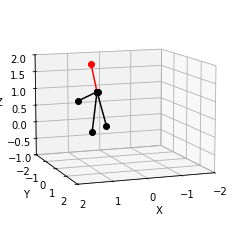

In [19]:
### Mocap Visualization & Validation

from matplotlib import animation

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.set(xlim3d=(-2, 2), xlabel="X",
       ylim3d=(-2, 2), ylabel="Y",
       zlim3d=(-1, 2), zlabel="Z")
ax.view_init(10, 70)

# Body part indices
SPINE, RIGHT_FOOT, RIGHT_HAND, LEFT_FOOT, HEAD, LEFT_HAND = 0, 1, 2, 3, 4, 5

# Skeletal connections from spine to all extremities
connections = [
    (SPINE, HEAD, "ro-"),        # spine to head (red)
    (SPINE, RIGHT_FOOT, "ko-"),  # spine to right foot
    (SPINE, RIGHT_HAND, "ko-"),  # spine to right hand
    (SPINE, LEFT_FOOT, "ko-"),   # spine to left foot
    (SPINE, LEFT_HAND, "ko-"),   # spine to left hand
]

rods = [ax.plot([], [], style)[0] for _start, _end, style in connections]

def plot_scene(frame_idx):
    frame = target_mocap_frames[frame_idx]
    for i, (start_idx, end_idx, _) in enumerate(connections):
        start_pos, end_pos = frame[start_idx], frame[end_idx]
        rods[i].set_data([start_pos[0], end_pos[0]], [start_pos[1], end_pos[1]])
        rods[i].set_3d_properties([start_pos[2], end_pos[2]])

def animate(frame_idx):
    if frame_idx > 1 and frame_idx % 20 == 0:
        print(f"Generating frame #{frame_idx}...")
    plot_scene(frame_idx)
    return rods

anim = animation.FuncAnimation(
    fig, animate, frames=total_render_frames, interval=33, blit=True
)
HTML(anim.to_html5_video())

### 3.3.2 Retarget our Motion Capture to our Figure using Inverse Kinematics


In [20]:
### Motion Capture IK Simulation

p.setAdditionalSearchPath(pd.getDataPath())
p.loadURDF("plane.urdf")

# Constants
IDX = dict(
    spine       = 0,
    r_foot      = 1,
    r_hand      = 2,
    l_foot      = 3,
    head        = 4,
    l_hand      = 5,
)

# 2. list end-effectors *and* their mocap source in the same order
MAPPING = [
    (name_to_transform["r_feet"],  "r_foot"),
    (name_to_transform["r_hand"],  "r_hand"),
    (name_to_transform["l_feet"],  "l_foot"),
    (name_to_transform["head"],    "head"),
    (name_to_transform["l_hand"],  "l_hand"),
]
n_dofs = len(transform_list_1dof)

n_dofs        = len(transform_list_1dof)
pixel_width   = 640
pixel_height  = 368
fps           = 30
video_path    = Path("./mocap_ik.mp4")
max_frames    = 300

# Move target glyphs off-screen
for uid in target_body_list:
    p.resetBasePositionAndOrientation(uid, [100, 100, 100], [0, 0, 0, 1])


In [21]:
### Retargeting Mocap to PyBullet via IK: Video Generation

# Simultaion
reset_simulation()
create_rigid_bodies()
q = np.zeros(n_dofs)           # warm-start pose

with iio.get_writer(Path("mocap_ik.mp4"), fps=30,
                    codec="libx264", macro_block_size=8) as writer:

    for f_idx in range(max_frames):
        frame = target_mocap_frames[f_idx]

        # build aligned lists -------------------------------------------------
        end_effectors = [pair[0] for pair in MAPPING]
        targets       = [frame[IDX[pair[1]], :3] for pair in MAPPING]

        # update red spheres so we can see the targets
        for uid, tgt in zip(target_body_list, targets):
            p.resetBasePositionAndOrientation(uid, tgt, [0,0,0,1])

        # IK solve ------------------------------------------------------------
        res = minimize(objective_function, x0=q, jac=gradient_function,
                       method="SLSQP", options={"ftol":1e-4, "disp":False})
        q = res.x
        set_joint_positions(q)

        for rb in body_list:
            rb.update_pybullet()
        p.stepSimulation()

        # capture -------------------------------------------------------------
        _, _, img, _, _ = p.getCameraImage(
            640, 368, viewMatrix_mocap, projectionMatrix,
            shadow=1, lightDirection=[1,1,1]
        )
        writer.append_data(np.asarray(img, np.uint8).reshape(368, 640, 4)[:, :, :3])

        if f_idx % 20 == 0:
            print(f"Rendered IK frame {f_idx}")

print("✓ Video written to mocap_ik.mp4")
display(Video("mocap_ik.mp4", embed=True,
              width=640, height=368,
              html_attributes="controls loop autoplay muted"))

Rendered IK frame 0
Rendered IK frame 20
Rendered IK frame 40
Rendered IK frame 60
Rendered IK frame 80
Rendered IK frame 100
Rendered IK frame 120
Rendered IK frame 140
Rendered IK frame 160
Rendered IK frame 180
Rendered IK frame 200
Rendered IK frame 220
Rendered IK frame 240
Rendered IK frame 260
Rendered IK frame 280
✓ Video written to mocap_ik.mp4


Your browser does not support the video tag.

# 4. Extra Questions

## 4.1 Discussing Motion Capture Results

For some motion capture data, the retargeted motion doesn't resemble the actual human actor. Discuss what causes this and what are some ways to make the motion of our robot resemble that of the human actor.

### 🚩 Extra Credit Task: Write your answer below (2 pts) 🚩

__write your answer here__

## 4.2. Memoization of `transform_between()`

The `transform_between()` function is one of the busiest functions in the code. First, count the number of times it is called during one evaluation of the objective function.

By caching the computation results, you may be able to save some function calls, which is called "*memoization*" (https://en.wikipedia.org/wiki/Memoization). Implement this caching mechanism and see if you can reduce the number of `transform_between()` function calls per objective evaluation.

**Note:** *don't forget to erase the cache when we change the pose.*
**Note:** Editing the code above may affect the autograding. Please back up your previous implementation and use the cell below as a submission area for your modified code.

### 🚩 Implement memoization for `transform_between()` by editing the code above directly and explain your implementation & results - number of function calls - in the markdown cell below (4 pts) 🚩

In [22]:
### Placeholder for Your Code, Copy and Paste your code here (4 pts)

def place_holder_transform_between(start, end):
  """This is a helper function to compute the transformation between start and
  end transformations.
  """
  if start == end:
    return np.identity(4)
  else:
    return transform_between(start, end.parent) @ end.local_transform()

(explain your answer here)

## 4.3. Never Leave The Targets

At the final stage of the Twister video (after adding the final constraint), some of the character's end-effectors may leave the targets temporarily during the interpolation of pose. Refer to the frame below as an example *(if you don't see something like it in the Twister video for some reason, please give it harder target configurations)*.

This is because we first solve the constrained IK problem once per stage (as each target is added), and then interpolate the motion freely in the pose space between the poses for each stage. Nothing forces the poses generated *during the interpolation* to satisfy all constraints that the targets specify.

Please update the motion interpolation algorithm to prevent this behavior.

**Hint:** *you may need to interpolate in the space of the targets instead, and solve the resulting IK problems more often.*
**Note:** Editing the code above may affect the autograding. Please back up your previous implementation and use the cell below as a submission area for your modified code.

### 🚩 edit the above code directly and explain your implementation below (4 pts) 🚩 

![Bad Frame](https://cc.gatech.edu/~sha9/public/P5-twister-bad.png)

In [23]:
# Placeholder for Your Code

(explain your answer here).